# Unsupervised ML Strategy with Fama-French 5-Factor Model

This notebook enhances the base unsupervised ML strategy by incorporating
Fama-French 5-factor rolling betas as additional clustering features.

**Features used for clustering (12 total):**
- 7 technical indicators: Garman-Klass Volatility, RSI, Bollinger Bands (low/mid/upper), ATR, MACD
- 5 Fama-French factor betas: Mkt-RF, SMB, VMG (HML), RMW, CMA

In [1]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import pandas_datareader.data as web
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import numpy as np
import yfinance as yf
import requests
import pandas_ta
from pypfopt.efficient_frontier import EfficientFrontier
from pypfopt import risk_models, expected_returns
import datetime as dt
import warnings
warnings.filterwarnings('ignore')

c:\Users\bedel\Downloads\Algorithmic Trading Strategies\venv\Lib\site-packages\pandas_ta\__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


## 1. Download S&P 500 Price Data (15 Years)

In [2]:
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies' 
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/128.0.0.0 Safari/537.36'}
response = requests.get(url, headers=headers)
response.raise_for_status()
sp500 = pd.read_html(response.text)[0]
sp500['Symbol'] = sp500['Symbol'].replace('.','-')
symbols_list = sp500['Symbol'].unique().tolist()

end_date = dt.datetime.today()
start_date = pd.to_datetime(end_date) - pd.DateOffset(365*15)

df = yf.download(tickers=symbols_list,
                 start=start_date,
                 end=end_date).stack()
df = df.drop(columns=['Adj Close'])
df.index.names = ['date', 'ticker']
df.columns.name = None
df.columns = df.columns.str.lower()
print(f'Downloaded {len(df)} rows for {df.index.get_level_values("ticker").nunique()} stocks')

[*********************100%***********************]  503 of 503 completed

2 Failed downloads:
['BF.B']: YFPricesMissingError('possibly delisted; no price data found  (1d 2011-04-01 19:14:41.134360 -> 2026-03-28 19:14:41.134360)')
['BRK.B']: YFTzMissingError('possibly delisted; no timezone found')


Downloaded 1791264 rows for 501 stocks


## 2. Calculate Technical Indicators

In [3]:
# Garman-Klass Volatility
df['garman-klass_volatility'] = (((np.log(df['high']) - np.log(df['low']))**2) / 2) - (2*np.log(2) - 1) * ((np.log(df['close']) - np.log(df['open']))**2)

# RSI (20-day, normalized)
def compute_rsi(close):
    rsi = pandas_ta.rsi(close=close, length=20)
    return rsi.sub(rsi.mean()).div(rsi.std())
df['rsi'] = df.groupby(level=1)['close'].transform(compute_rsi)

# Bollinger Bands (20-day, log prices)
df['bb_low'] = df.groupby(level=1)['close'].transform(lambda x: pandas_ta.bbands(close=np.log1p(x), length=20).iloc[:, 0])
df['bb_mid'] = df.groupby(level=1)['close'].transform(lambda x: pandas_ta.bbands(close=np.log1p(x), length=20).iloc[:, 1])
df['bb_upper'] = df.groupby(level=1)['close'].transform(lambda x: pandas_ta.bbands(close=np.log1p(x), length=20).iloc[:, 2])

# ATR (14-day, normalized)
def compute_atr(stock_data):
    atr = pandas_ta.atr(high=stock_data['high'], low=stock_data['low'], close=stock_data['close'], length=14)
    return atr.sub(atr.mean()).div(atr.std())
df['atr'] = df.groupby(level=1).apply(compute_atr).droplevel(0)

# MACD (12/26 EMA, normalized)
def compute_macd(close, fast=12, slow=26, signal=9):
    close = pd.to_numeric(close, errors='coerce').astype(float)
    if close.isna().all():
        return pd.Series(np.nan, index=close.index, dtype=float)
    fast_ema = close.ewm(span=fast, min_periods=fast, adjust=False).mean()
    slow_ema = close.ewm(span=slow, min_periods=slow, adjust=False).mean()
    macd_line = fast_ema - slow_ema
    mean = macd_line.mean(skipna=True)
    std = macd_line.std(skipna=True)
    if pd.isna(mean) or pd.isna(std) or std == 0:
        return pd.Series(np.nan, index=close.index, dtype=float)
    return ((macd_line - mean) / std).astype(float)

df['macd'] = df.groupby(level=1, group_keys=False)['close'].apply(compute_macd)
df['dollar_volume'] = (df['close']*df['volume']) / 1e6
print('Technical indicators calculated.')

Technical indicators calculated.


## 3. Monthly Aggregation & Liquidity Filter (Top 150)

In [4]:
last_cols = [c for c in df.columns.unique(level=0) if c not in ['dollar_volume', 'volume', 'open', 'high', 'low', 'close']]

agg_data = pd.concat([df['dollar_volume'].groupby(level=1).resample('M', level=0).mean().to_frame('dollar_volume'), 
          df[['close'] + last_cols].groupby(level=1).resample('M', level=0).last()], axis=1).dropna()

liquidity = df['dollar_volume'].unstack('ticker').rolling(5*12).mean().stack().to_frame('dollar_volume')
liquidity['dollar_vol_rank'] = liquidity.groupby(level=0)['dollar_volume'].rank(ascending=False)
data = agg_data.join(liquidity['dollar_vol_rank'])
data = data[data['dollar_vol_rank'] < 151].dropna(axis=0)
data = data.drop(columns=['dollar_vol_rank','dollar_volume'])

def calculate_returns(df):
    outlier_cutoff = 0.005
    lags = [1]
    for lag in lags:
        df[f'return_{lag}m'] = (df['close']
                            .pct_change(lag)
                            .pipe(lambda x: x.clip(lower=x.quantile(outlier_cutoff), upper=x.quantile(1-outlier_cutoff)))
                            .add(1).pow(1/lag).sub(1))
    return df
data = data.groupby(level=1, group_keys=False).apply(calculate_returns).dropna().sort_index(level=1, ascending=False)
print(f'Monthly data: {len(data)} rows, {data.index.get_level_values("ticker").nunique()} unique stocks')

Monthly data: 18476 rows, 325 unique stocks


## 4. Download Fama-French 5-Factor Data & Rolling Regression

In [5]:
factor_data = web.DataReader('F-F_Research_Data_5_Factors_2x3', 'famafrench', start=start_date)[0]
factor_data.index = factor_data.index.to_timestamp()
factor_data.index.name = 'date'
factor_data = factor_data.resample('M').last().div(100)
factor_data.rename(columns={'HML': 'VMG'}, inplace=True)
factors = ['Mkt-RF','SMB','VMG','RMW','CMA']

regression_input = (
    data.reset_index()
    .merge(factor_data, on='date', how='inner')
    .set_index(['date', 'ticker'])
    .sort_index()
)
regression_input['return_1m'] = regression_input['return_1m'] - regression_input['RF']
observations = regression_input.groupby('ticker').size()
valid_tickers = observations[observations >= 10].index
regression_input = (regression_input[regression_input.index.get_level_values('ticker').isin(valid_tickers)]
                    ).drop(columns=['RF','close'])

print(f'Fama-French factors loaded. Running rolling regressions for {len(valid_tickers)} tickers...')

Fama-French factors loaded. Running rolling regressions for 258 tickers...


In [6]:
def rolling_regression(group, factors, target='return_1m', window=12*5, min_nobs=15):
    results = pd.DataFrame(index=group.index, columns=factors, dtype=float)
    depen = group[target].values
    indep = group[factors].values
    non_empty_rows = ~(pd.isna(depen) | pd.isna(indep).any(axis=1))
    if non_empty_rows.sum() < min_nobs:
        return results
    for i in range(min_nobs-1, len(group)):
        start_idx = max(0, i - window + 1)
        end_idx = i + 1
        depen_data = depen[start_idx:end_idx]
        indep_data = indep[start_idx:end_idx]
        non_empty_data = ~(pd.isna(depen_data) | pd.isna(indep_data).any(axis=1))
        if non_empty_data.sum() >= min_nobs:
            depen_data = depen_data[non_empty_data]
            indep_data = indep_data[non_empty_data]
            try:
                reg = LinearRegression(fit_intercept=False)
                reg.fit(indep_data, depen_data)
                results.iloc[i] = reg.coef_
            except Exception:
                continue
    return results

betas = (
    regression_input.groupby('ticker', group_keys=False)
    .apply(lambda x: rolling_regression(x, factors))
).dropna(axis=0)

feature_target_cols = ['garman-klass_volatility', 'rsi', 'bb_low', 'bb_mid', 'bb_upper', 'atr', 'macd']
betas = betas.shift().join(data[feature_target_cols], how='left').dropna(axis=0)
betas.loc[:,factors] = betas.groupby('ticker', group_keys=False)[factors].apply(lambda x: x.fillna(x.mean()))
betas = betas.dropna()
print(f'Rolling regression complete. {len(betas)} stock-month observations.')

Rolling regression complete. 14665 stock-month observations.


## 5. K-Means Clustering (4 Clusters)

In [7]:
def get_clusters(df):
    n_clusters = 4
    if len(df) < n_clusters:
        df['cluster'] = -1
        return df
    features_cols = df.columns.drop('cluster', errors='ignore')
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(df[features_cols])
    df['cluster'] = KMeans(n_clusters=4, random_state=0, init='k-means++', n_init=10).fit(scaled_features).labels_
    return df

betas = betas.groupby('date', group_keys=False).apply(get_clusters)
print(f'Clustering complete. Cluster distribution (last month):')
last_date = betas.index.get_level_values('date').max()
print(betas.xs(last_date, level='date')['cluster'].value_counts().sort_index())

Clustering complete. Cluster distribution (last month):
cluster
0    41
1    47
2     3
3    41
Name: count, dtype: int64


## 6. Cluster Visualization

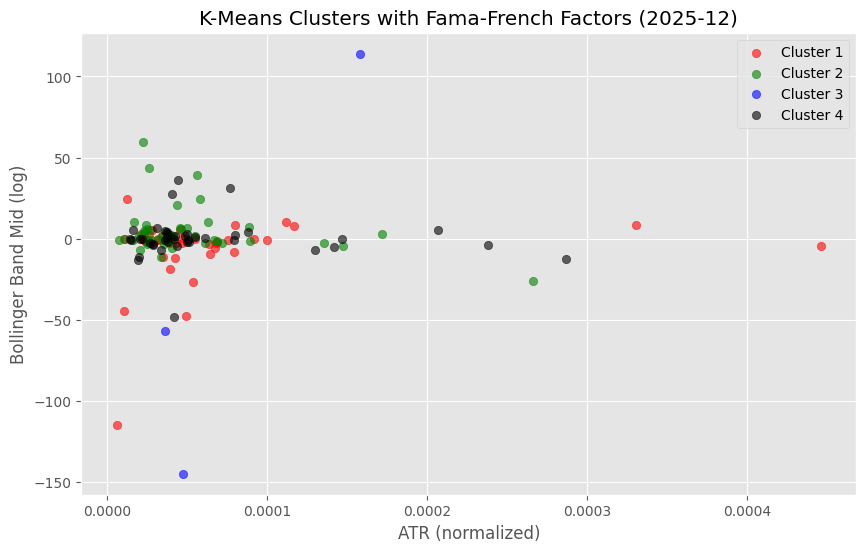

In [8]:
plt.style.use('ggplot')
g = betas.xs(last_date, level='date')
colors = {0: 'red', 1: 'green', 2: 'blue', 3: 'black'}
labels = {0: 'Cluster 1', 1: 'Cluster 2', 2: 'Cluster 3', 3: 'Cluster 4'}

plt.figure(figsize=(10, 6))
for cluster_id in range(4):
    mask = g['cluster'] == cluster_id
    plt.scatter(g.loc[mask].iloc[:, 5], g.loc[mask].iloc[:, 3],
                color=colors[cluster_id], label=labels[cluster_id], alpha=0.6)
plt.legend()
plt.title(f'K-Means Clusters with Fama-French Factors ({last_date.strftime("%Y-%m")})')
plt.xlabel('ATR (normalized)')
plt.ylabel('Bollinger Band Mid (log)')
plt.savefig('../../results/fama_french_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Portfolio Construction & Optimization (Cluster 3)

In [9]:
filtered_df = betas[betas['cluster']==3].copy()
filtered_df = filtered_df.reset_index(level='ticker')
filtered_df.index = filtered_df.index + pd.DateOffset(1)
filtered_df = filtered_df.reset_index().set_index(['date', 'ticker'])
dates = filtered_df.index.get_level_values(level='date').unique().to_list()
fixed_dates = {}
for d in dates:
    fixed_dates[d.strftime('%Y-%m-%d')] = filtered_df.xs(d, level='date').index.to_list()

stocks = data.index.get_level_values('ticker').unique().to_list()
new_df = yf.download(tickers=stocks,
                      start=data.index.get_level_values('date').min()-pd.DateOffset(months=12),
                      end=data.index.get_level_values('date').max())

def optimize_weights(prices, lower_bound=0):
    returns = expected_returns.mean_historical_return(prices=prices, frequency=252)
    cs = risk_models.CovarianceShrinkage(prices, frequency=252)
    cov = cs.ledoit_wolf()
    ef = EfficientFrontier(expected_returns=returns, cov_matrix=cov,
                           weight_bounds=(lower_bound, 1), solver='SCS')
    ef.max_sharpe()
    return ef.clean_weights()

returns_dataframe = np.log(new_df['Close']).diff()

portfolio_dfs = []
for start_date in fixed_dates.keys():
    end_date = (pd.to_datetime(start_date)+pd.offsets.MonthEnd(0)).strftime('%Y-%m-%d')
    cols = fixed_dates[start_date]
    optimization_start_date = (pd.to_datetime(start_date)-pd.DateOffset(months=12)).strftime('%Y-%m-%d')
    optimization_end_date = (pd.to_datetime(start_date)-pd.DateOffset(days=1)).strftime('%Y-%m-%d')
    optimization_df = new_df.loc[optimization_start_date:optimization_end_date,'Close'][cols]
    success = False
    try:
        weights = optimize_weights(optimization_df, lower_bound=0.001)
        weights = pd.DataFrame(weights, index=[0])
        success = True
    except ValueError:
        print(f'Max Sharpe failed for {start_date}, using equal weights')
    if not success:
        weights = pd.DataFrame(
            [1/len(optimization_df.columns) for i in range(len(optimization_df.columns))],
            index=optimization_df.columns.to_list(),
            columns=pd.Series(0)).T
    temp_df = returns_dataframe[start_date:end_date]
    temp_df = temp_df.stack().to_frame('Return').reset_index(level=0).merge(
        weights.stack().to_frame('Weight').reset_index(level=0, drop=True),
        left_index=True, right_index=True
    ).reset_index().set_index(['Date', 'Ticker'])
    temp_df['Weighted Return'] = temp_df['Return'] * temp_df['Weight']
    temp_df = temp_df.groupby(level=0)['Weighted Return'].sum().to_frame('Portfolio Return')
    portfolio_dfs.append(temp_df)

portfolio_df = pd.concat(portfolio_dfs).drop_duplicates()
print(f'Portfolio constructed: {len(portfolio_df)} trading days')

[*********************100%***********************]  325 of 325 completed

3 Failed downloads:
['PNC', 'SYK', 'CDNS']: Timeout('Failed to perform, curl: (28) Connection timed out after 10004 milliseconds. See https://curl.se/libcurl/c/libcurl-errors.html first for more details.')


Max Sharpe failed for 2016-04-01, using equal weights
Max Sharpe failed for 2016-11-01, using equal weights
Max Sharpe failed for 2017-04-01, using equal weights
Portfolio constructed: 2271 trading days


## 8. Performance: Strategy vs SPY Buy & Hold

[*********************100%***********************]  1 of 1 completed


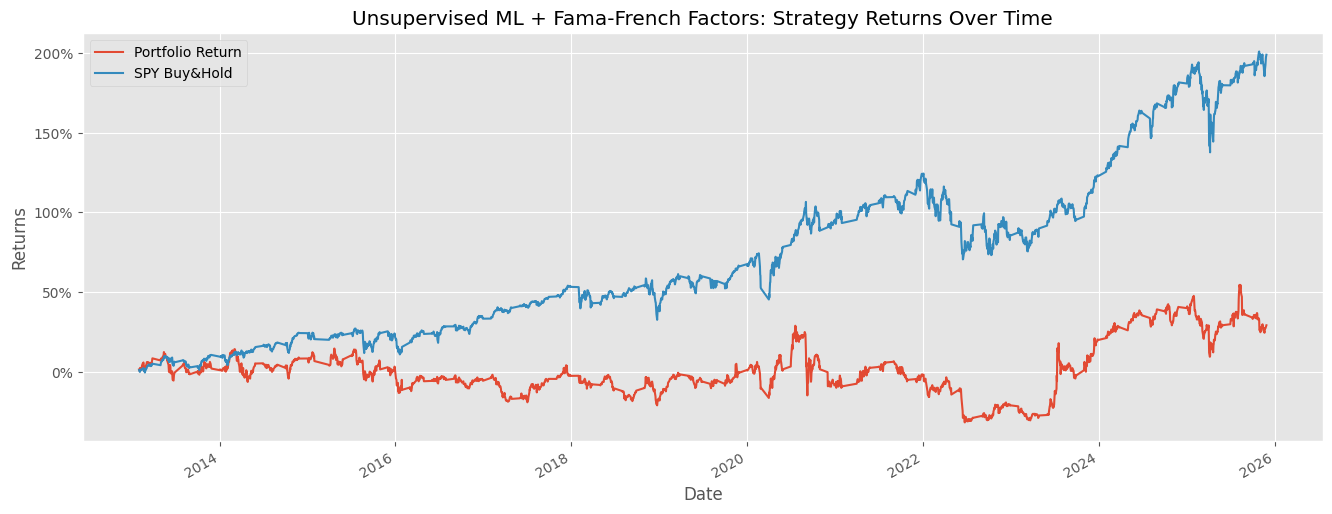

In [10]:
end_date = dt.datetime.today()
start_date = pd.to_datetime(end_date) - pd.DateOffset(365*15)
spy = yf.download(tickers='SPY', start=start_date, end=end_date)
spy_return = np.log(spy['Close']).diff().dropna().rename({'SPY':'SPY Buy&Hold'}, axis=1)
spy_return.columns.name = None
portfolio_df = portfolio_df.merge(spy_return, left_index=True, right_index=True).sort_index()

plt.style.use('ggplot')
portfolio_cumulative_returns = np.exp(np.log1p(portfolio_df).cumsum())
total_percentage_return = portfolio_cumulative_returns - 1
total_percentage_return[:end_date].plot(figsize=(16,6))
plt.title('Unsupervised ML + Fama-French Factors: Strategy Returns Over Time')
plt.ylabel('Returns')
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1))
plt.savefig('../../results/fama_french_ml_returns.png', dpi=150, bbox_inches='tight')
plt.show()